# TASK 3: Data analysis

**Project:** Robustness of AI-based content moderation to character-level obfuscation
**Authors:** Azaliya Sultanbek, Zeinep Egemkul (Narxoz University)

**Questions.** H1 (from Task 2): does obfuscation lower the recall of harmful posts by at least 5 pp?
H2 (added in Task 3): does simple text normalisation (`src/normalize.py`) bring the lost recall back?

**Data.** TweetEval-hate test set (2,970 tweets, our 4 obfuscations) and NoisyHate (1,339 toxic comments,
each with a version disguised by real people, Ye et al. 2023).

Steps: 1) load the raw log and drop warm-up, 2) statistics, 3) hypothesis tests and guardrails, 4) figures,
5) reproducibility check. The logic is in `src/process_data.py` and `src/visualize.py`. Run with *Restart & Run All*.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import process_data as pdx, visualize as viz

np.random.seed(42)   # fixed seed; the bootstrap uses default_rng(42) as well
pd.set_option("display.float_format", "{:.3f}".format, "display.width", 160)

## 1. Data ingestion and warm-up filtering

`test_run.jsonl` has 4 kinds of lines: `meta` (settings and hardware), `quality` (which posts were flagged,
as a string of 0/1), `latency` (time of every model call) and `memory` (peak RAM).
The first calls of every latency run are slow (the program "wakes up": caches, memory allocation).
They are marked `warmup` and removed, because they do not show the normal speed.

In [2]:
meta, lat, q, mem = pdx.load_log(ROOT / "data/raw/test_run.jsonl")
print("hardware:", meta["environment"]["cpu_logical_cores"], "CPU cores,", meta["environment"]["ram_total_mb"], "MB RAM | seed", meta["seed"])
print("models in the log:", list(q.model.unique()))
ev, wu = pdx.drop_warmup(lat)
print(f"latency calls: {len(lat)} -> warm-up dropped: {len(wu)}, kept: {len(ev)}")
# how much slower is a warm-up call than a normal one (batch size 1)?
cmp = pd.DataFrame({"warmup_median_ms": wu.groupby(["model", "prep", "batch_size"]).ms_per_item.median(),
                    "eval_median_ms": ev.groupby(["model", "prep", "batch_size"]).ms_per_item.median()})
cmp["ratio"] = cmp.warmup_median_ms / cmp.eval_median_ms
cmp

hardware: 8 CPU cores, 8192 MB RAM | seed 42
models in the log: ['tfidf_word_lr', 'tfidf_char_lr', 'roberta_hate']
latency calls: 4650 -> warm-up dropped: 270, kept: 4380


warmup_median_ms  eval_median_ms  ratio
model         prep       batch_size                                         
roberta_hate  normalized 1                     82.926          66.332  1.250
                         8                     54.275          45.455  1.194
                         64                    46.934          50.143  0.936
              raw        1                     72.339          62.537  1.157
                         8                     51.974          43.874  1.185
                         64                    46.464          49.590  0.937
tfidf_char_lr normalized 1                      0.917           0.597  1.537
                         8                      0.313           0.285  1.100
                         64                     0.232           0.237  0.983
              raw        1                      0.734           0.507  1.447
                         8                      0.245           0.224  1.096
                         64                     0.171           0.175  0.980
tfidf_word_lr normalized 1                      0.574           0.445  1.290
                         8                      0.142           0.132  1.077
                         64                     0.088           0.090  0.975
              raw        1                      0.411           0.379  1.084
                         8                      0.071           0.067  1.052
                         64                     0.026           0.027  0.981

## 2. Statistics: latency and throughput

Latency per post: median, p25, p75, p95, p99, mean and SD. The median is the main number because a few very slow
calls pull the mean up. 95% CI of the median = bootstrap (2,000 resamples). Throughput = posts per second, per repeat.

In [3]:
lat_t = pdx.latency_table(ev)
lat_t[["model", "prep", "batch_size", "n", "median_ms", "median_ci_low", "median_ci_high", "p95_ms", "p99_ms",
       "mean_ms", "sd_ms", "throughput", "throughput_ci_low", "throughput_ci_high"]]

,model,prep,batch_size,n,median_ms,median_ci_low,median_ci_high,p95_ms,p99_ms,mean_ms,sd_ms,throughput,throughput_ci_low,throughput_ci_high
0,tfidf_word_lr,raw,1,640,0.379,0.378,0.380,0.412,0.432,0.382,0.016,2614.706,2606.985,2621.405
1,tfidf_word_lr,raw,8,80,0.067,0.066,0.068,0.071,0.072,0.067,0.003,14975.654,14875.899,15069.975
2,tfidf_word_lr,raw,64,10,0.027,0.026,0.027,0.027,0.028,0.027,0.001,37395.951,37255.113,37582.452
3,tfidf_word_lr,normalized,1,640,0.445,0.441,0.449,0.554,0.588,0.455,0.050,2196.698,2176.845,2215.651
4,tfidf_word_lr,normalized,8,80,0.132,0.129,0.135,0.149,0.151,0.132,0.010,7590.035,7572.965,7607.104
5,tfidf_word_lr,normalized,64,10,0.090,0.088,0.090,0.091,0.091,0.089,0.002,11211.748,11156.025,11267.113
6,tfidf_char_lr,raw,1,640,0.507,0.497,0.514,0.733,0.767,0.534,0.100,1872.448,1863.931,1880.966
7,tfidf_char_lr,raw,8,80,0.224,0.214,0.230,0.245,0.255,0.218,0.024,4578.709,4546.657,4612.151
8,tfidf_char_lr,raw,64,10,0.175,0.172,0.178,0.179,0.179,0.175,0.003,5721.409,5708.044,5734.774
9,tfidf_char_lr,normalized,1,640,0.597,0.585,0.606,0.922,2.462,0.715,0.918,1471.183,1192.011,1629.649


In [4]:
# cost of normalisation in time: extra milliseconds per post at batch size 1
b1 = lat_t[lat_t.batch_size == 1].set_index(["model", "prep"]).median_ms.unstack()
b1["extra_ms"] = b1.normalized - b1.raw
b1

prep,normalized,raw,extra_ms
model,,,
roberta_hate,66.332,62.537,3.795
tfidf_char_lr,0.597,0.507,0.090
tfidf_word_lr,0.445,0.379,0.066


## 3. Detection quality, hypotheses and guardrails

**Recall** = share of harmful posts that were caught. **FPR** = share of normal posts flagged by mistake.

In [5]:
qt = pdx.quality_table(q)
qt[["model", "prep", "dataset", "condition", "recall", "recall_ci_low", "recall_ci_high", "fpr", "error_rate"]]

,model,prep,dataset,condition,recall,recall_ci_low,recall_ci_high,fpr,error_rate
0,tfidf_word_lr,raw,tweeteval,none,0.952,0.939,0.963,0.891,0.000
1,tfidf_word_lr,raw,tweeteval,leetspeak,0.869,0.851,0.888,0.765,0.000
2,tfidf_word_lr,raw,tweeteval,char_insert,0.848,0.829,0.868,0.743,0.000
3,tfidf_word_lr,raw,tweeteval,homoglyph,0.863,0.843,0.882,0.776,0.000
4,tfidf_word_lr,raw,tweeteval,char_swap,0.865,0.846,0.884,0.752,0.000
5,tfidf_word_lr,raw,val,none,0.782,0.742,0.820,0.323,0.000
6,tfidf_word_lr,raw,noisyhate,clean,0.214,0.193,0.237,NaN,0.000
7,tfidf_word_lr,raw,noisyhate,human_perturbed,0.178,0.158,0.199,NaN,0.000
8,tfidf_word_lr,normalized,tweeteval,none,0.951,0.938,0.962,0.887,0.000
9,tfidf_word_lr,normalized,tweeteval,leetspeak,0.951,0.938,0.962,0.887,0.000


**Tests.** Every comparison uses the *same* posts in two versions (paired design): one-sided exact McNemar test,
Holm correction inside each family, paired bootstrap 95% CI. A row counts as *supported* only if
Holm-p < 0.05 **and** the difference is ≥ 5 pp (rule from the methodology card).

In [6]:
tests = pdx.hypothesis_tests(q)
tests[["family", "model", "comparison", "recall_first", "recall_second", "delta_pp", "delta_ci_low_pp",
       "delta_ci_high_pp", "p_holm", "supported"]]

,family,model,comparison,recall_first,recall_second,delta_pp,delta_ci_low_pp,delta_ci_high_pp,p_holm,supported
0,H1,tfidf_word_lr,tweeteval: clean vs leetspeak,0.952,0.869,8.307,6.550,9.904,0.000,True
1,H2,tfidf_word_lr,tweeteval leetspeak: normalized vs raw,0.951,0.869,8.227,6.470,9.904,0.000,True
2,H1,tfidf_word_lr,tweeteval: clean vs char_insert,0.952,0.848,10.383,8.387,12.300,0.000,True
3,H2,tfidf_word_lr,tweeteval char_insert: normalized vs raw,0.951,0.848,10.304,8.307,12.222,0.000,True
4,H1,tfidf_word_lr,tweeteval: clean vs homoglyph,0.952,0.863,8.866,7.107,10.783,0.000,True
5,H2,tfidf_word_lr,tweeteval homoglyph: normalized vs raw,0.951,0.863,8.786,6.949,10.703,0.000,True
6,H1,tfidf_word_lr,tweeteval: clean vs char_swap,0.952,0.865,8.706,6.949,10.543,0.000,True
7,H2,tfidf_word_lr,tweeteval char_swap: normalized vs raw,0.859,0.865,-0.559,-1.358,0.160,1.000,False
8,H1,tfidf_word_lr,noisyhate: clean vs human_perturbed,0.214,0.178,3.585,2.240,5.004,0.000,False
9,H2,tfidf_word_lr,noisyhate human_perturbed: normalized vs raw,0.187,0.178,0.822,-0.301,1.942,0.443,False


In [7]:
# Plain-language summary, computed from the table above
for m in tests.model.unique():
    h1 = tests[(tests.family == "H1") & (tests.model == m) & tests.comparison.str.startswith("tweeteval")]
    print(f"{m}: H1 supported for {h1.supported.sum()} of {len(h1)} obfuscations, recall drop {h1.delta_pp.min():.1f}-{h1.delta_pp.max():.1f} pp")
    lost = tests[(tests.family == "H1") & (tests.model == m) & tests.comparison.str.startswith("noisyhate")].delta_pp.iloc[0]
    back = tests[(tests.family == "H2") & (tests.model == m) & tests.comparison.str.startswith("noisyhate")].delta_pp.iloc[0]
    print(f"   NoisyHate (real people): obfuscation costs {lost:.1f} pp, normalisation gives back {back:.1f} pp = {back / lost:.0%} of the loss")

tfidf_word_lr: H1 supported for 4 of 4 obfuscations, recall drop 8.3-10.4 pp
   NoisyHate (real people): obfuscation costs 3.6 pp, normalisation gives back 0.8 pp = 23% of the loss
tfidf_char_lr: H1 supported for 3 of 4 obfuscations, recall drop 5.0-18.3 pp
   NoisyHate (real people): obfuscation costs 2.7 pp, normalisation gives back 1.0 pp = 36% of the loss
roberta_hate: H1 supported for 3 of 4 obfuscations, recall drop 3.0-12.6 pp
   NoisyHate (real people): obfuscation costs 5.2 pp, normalisation gives back 3.4 pp = 65% of the loss


**Guardrails** (methodology card): FPR ≤ 0.20, p95 latency ≤ 100 ms at batch size 1, peak RAM ≤ 4,096 MB, no failed posts.
The validation split is shown next to the test split: if FPR is much higher on test than on validation, the test
data differ from the training data (distribution shift).

In [8]:
g = qt[qt.dataset.isin(["tweeteval", "val"]) & (qt.condition == "none")][["model", "prep", "dataset", "fpr"]]
g = g.pivot_table(index=["model", "prep"], columns="dataset", values="fpr").rename(columns=lambda c: f"fpr_{c}")
g["p95_ms_bs1"] = lat_t[lat_t.batch_size == 1].set_index(["model", "prep"]).p95_ms
g["peak_ram_mb"] = mem.set_index(["model", "prep"]).peak_rss_mb
g["max_error_rate"] = qt.groupby(["model", "prep"]).error_rate.max()
g["fpr_ok"], g["latency_ok"], g["ram_ok"] = g.fpr_tweeteval <= 0.20, g.p95_ms_bs1 <= 100, g.peak_ram_mb <= 4096
g

dataset                   fpr_tweeteval  fpr_val  ...  latency_ok  ram_ok
model         prep                                ...                    
roberta_hate  normalized          0.233    0.166  ...        True    True
              raw                 0.201    0.133  ...        True    True
tfidf_char_lr normalized          0.920    0.300  ...        True    True
              raw                 0.923    0.291  ...        True    True
tfidf_word_lr normalized          0.887    0.316  ...        True    True
              raw                 0.891    0.323  ...        True    True

[6 rows x 8 columns]

## 4. Figures

Units on every axis, 95% CI on every point, colour-blind palette plus markers/line styles/hatches.
Each figure is saved to `reports/figures/` as `.pdf` and 300-dpi `.png`.

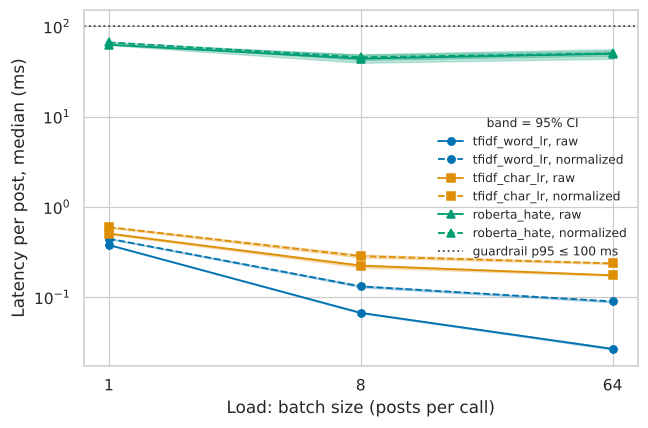

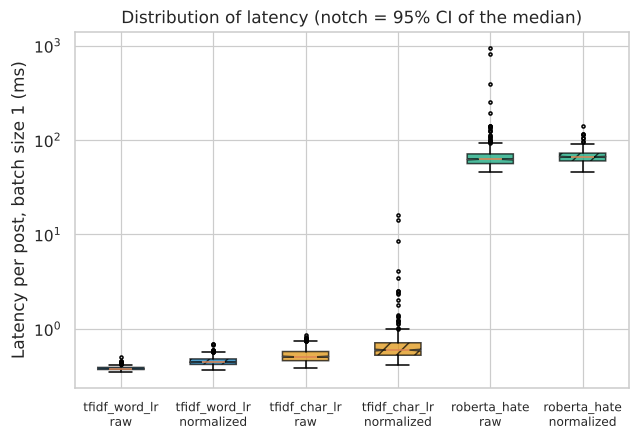

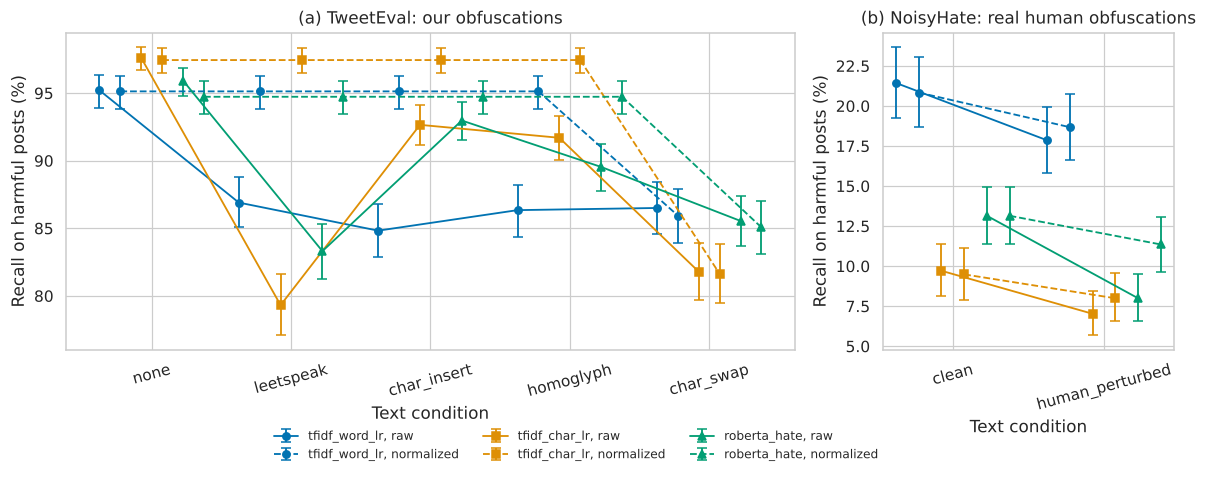

In [9]:
viz.fig1_latency_vs_load(lat_t)
viz.fig2_distribution_boxplot(ev)
_ = viz.fig3_recall(qt)

## 5. Save tables and check reproducibility

In [10]:
out = ROOT / "data/processed"
qt.to_csv(out / "metrics_summary.csv", index=False, float_format="%.4f")
lat_t.to_csv(out / "latency_summary.csv", index=False, float_format="%.4f")
tests.to_csv(out / "hypothesis_tests.csv", index=False, float_format="%.6g")
same = pdx.latency_table(ev).equals(lat_t) and pdx.hypothesis_tests(q).equals(tests)
print("second calculation gives identical numbers:", same)
assert same

second calculation gives identical numbers: True


## 6. Limitations

* Synthetic obfuscations are partly the inverse of the normalisation rules, so the near-full recovery on TweetEval is
  expected; the honest test of the method is NoisyHate (real human obfuscations).
* NoisyHate is toxic Jigsaw comments while the models were trained on hate speech (HatEval), so absolute recall there is low;
  only the paired differences are interpreted.
* Large distribution shift between HatEval train/validation and test for the TF-IDF models (FPR ≈ 0.3 on validation vs ≈ 0.9 on test);
  RoBERTa, pre-trained on other data, has FPR ≈ 0.2 on test.
* Small effects (about 1 pp) differ slightly between computers (a first run on an x86 CPU vs. the final run on Apple M-series),
  so only effects with clear CIs are interpreted.
* English only, CPU only (Apple M-series laptop, 8 cores), latency measured on 128 posts × 5 repeats.